# Demo STING trên dữ liệu giả lập (Phase 1)

Notebook kiểm tra trực quan thuật toán **STING tự viết** (`src/sting.py`):
lưới phân cấp → thống kê từng ô → ô "dày" → gom cụm liền kề.

- Dữ liệu: 2 cụm blob 2D tách biệt (tổng 240 điểm), seed cố định.
- Kỳ vọng: STING tách đúng 2 cụm (ARI >= 0.9); độ nhạy tham số sẽ khảo sát ở Phase 4.


In [1]:
import sys
from pathlib import Path

# Cho phép import `sting` / `fig_style` dù kernel chạy từ notebooks/ hay từ gốc repo
ROOT = None
for cand in (Path.cwd(), Path.cwd().parent):
    if (cand / "src" / "sting.py").exists():
        ROOT = cand
        sys.path.insert(0, str(cand / "src"))
        sys.path.insert(0, str(cand / "scripts"))
        break

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from sklearn.datasets import make_blobs
from sklearn.metrics import adjusted_rand_score

from sting import STING
from fig_style import (PALETTE, CLUSTER_COLORS, CLUSTER_LABELS,
                       apply_style, new_fig, add_source, save_png)

# rcParams trình bày chuẩn repo (font/palette/DPI) — chỉ tác động lớp vẽ hình
apply_style()

# Hình lưu results/figs/ theo gốc repo, không phụ thuộc cwd của kernel
OUT_FIG = (ROOT or Path.cwd()) / "results" / "figs" / "00_synthetic_sting.png"

print("import OK")

import OK


## 1. Sinh dữ liệu giả lập

Hai cụm Gauss tách biệt hoàn toàn — trường hợp "dễ" để kiểm tra thuật toán chạy đúng trước khi dùng dữ liệu thật.

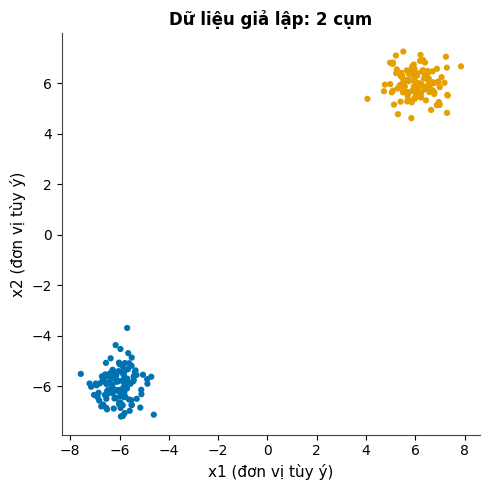

shape: (240, 2)


In [2]:
X, y_true = make_blobs(
    n_samples=240, centers=[(-6, -6), (6, 6)], cluster_std=0.6, random_state=42
)

# Palette chuẩn repo: cụm 0 = xanh dương, cụm 1 = cam (Okabe-Ito, CVD-safe)
fig, ax = new_fig(target=None, figsize=(5, 5))
ax.scatter(X[:, 0], X[:, 1], c=[CLUSTER_COLORS[int(v)] for v in y_true], s=12)
ax.set_title("Dữ liệu giả lập: 2 cụm")
# make_blobs không có đơn vị vật lý — ghi rõ "đơn vị tùy ý" trên nhãn trục
ax.set_xlabel("x1 (đơn vị tùy ý)"); ax.set_ylabel("x2 (đơn vị tùy ý)")
fig.tight_layout()
plt.show()

print("shape:", X.shape)

## 2. Xây lưới phân cấp STING

- Mức 0: 1 ô bao trùm toàn bộ dữ liệu.
- Mỗi mức kế tiếp chia mỗi chiều thành `factor` phần (ở đây factor = 4).
- Mỗi ô lưu thống kê count/mean/std/min/max theo từng chiều — dữ liệu chỉ bị quét 1 lượt cho mỗi mức.

In [3]:
model = STING(n_levels=3, factor=4, min_count=3).fit(X)

for level in range(3):
    cells = model.cells_[level]
    counts = np.array([c.count for c in cells.values()])
    print(f"mức {level}: {len(cells)} ô có dữ liệu, tổng điểm = {counts.sum()}, ô dày nhất = {counts.max()} điểm")

mức 0: 1 ô có dữ liệu, tổng điểm = 240, ô dày nhất = 240 điểm
mức 1: 2 ô có dữ liệu, tổng điểm = 240, ô dày nhất = 120 điểm
mức 2: 21 ô có dữ liệu, tổng điểm = 240, ô dày nhất = 45 điểm


## 3. Trực quan hóa lưới mức 2 và mật độ ô

Mỗi ô vẽ một hình chữ nhật; độ đậm thể hiện số điểm trong ô (mật độ).

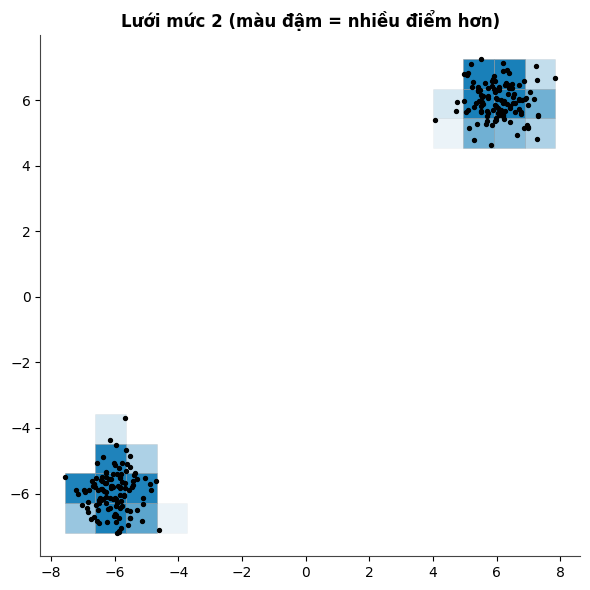

In [4]:
level = 2
step_x = (model.bounds_max_[0] - model.bounds_min_[0]) / (model.factor ** level)
step_y = (model.bounds_max_[1] - model.bounds_min_[1]) / (model.factor ** level)

fig, ax = new_fig(target=None, figsize=(6, 6))
for cell in model.cells_[level].values():
    x0, y0 = cell.bounds_min
    ax.add_patch(plt.Rectangle((x0, y0), step_x, step_y,
                               facecolor=PALETTE["blue"], alpha=min(0.08 * cell.count, 0.9),
                               edgecolor=PALETTE["gray"], linewidth=0.4))
ax.scatter(X[:, 0], X[:, 1], s=8, c="black")
ax.set_title(f"Lưới mức {level} (màu đậm = nhiều điểm hơn)")
fig.tight_layout()
plt.show()

## 4. Gom cụm và đối chiếu nhãn thật

Ô "dày" = count >= `min_count`. Các ô dày liền kề (kề mặt) gom thành một cụm;
điểm thuộc ô không dày nhận nhãn -1 (nhiễu).

ARI = 0.950 | tỷ lệ nhiễu = 2.5% | số cụm = 2


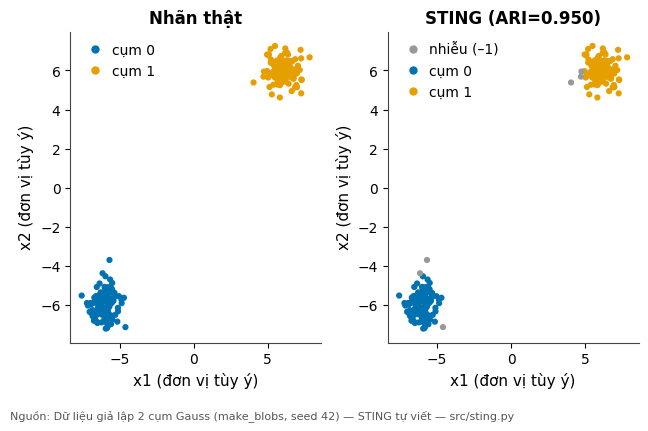

In [5]:
labels = model.cluster(level=2, connectivity=1)
ari = adjusted_rand_score(y_true, labels)
noise = (labels == -1).mean()
print(f"ARI = {ari:.3f} | tỷ lệ nhiễu = {noise:.1%} | số cụm = {model.n_clusters_}")

# Palette chuẩn repo: -1 = xám (nhiễu), 0 = xanh dương, 1 = cam
fig, axes = new_fig(target="docx", ncols=2)
axes[0].scatter(X[:, 0], X[:, 1], c=[CLUSTER_COLORS[int(v)] for v in y_true], s=12)
axes[0].set_title("Nhãn thật")
axes[1].scatter(X[:, 0], X[:, 1], c=[CLUSTER_COLORS[int(v)] for v in labels], s=12)
axes[1].set_title(f"STING (ARI={ari:.3f})")

def legend_clusters(ax, values):
    # Chú giải palette/nhãn chuẩn repo — chỉ gồm nhãn thật sự có trong dữ liệu
    handles = [
        Line2D([0], [0], marker="o", linestyle="", markersize=5,
               color=CLUSTER_COLORS.get(int(v), "#333333"),
               label=CLUSTER_LABELS.get(int(v), str(int(v))))
        for v in sorted({int(v) for v in values})
    ]
    ax.legend(handles=handles, loc="best", handletextpad=0.2, borderaxespad=0.4)

legend_clusters(axes[0], y_true)
legend_clusters(axes[1], labels)
# make_blobs không có đơn vị vật lý — ghi rõ "đơn vị tùy ý" trên cả 4 nhãn trục
for ax in axes:
    ax.set_xlabel("x1 (đơn vị tùy ý)"); ax.set_ylabel("x2 (đơn vị tùy ý)")

# Dòng nguồn: dữ liệu giả lập sinh tại chỗ (seed 42), không có PROVENANCE.md
# nên KHÔNG truyền `retrieved` — helper cấm tự điền ngày lấy dữ liệu.
add_source(fig, "Dữ liệu giả lập 2 cụm Gauss (make_blobs, seed 42)",
           extra="STING tự viết — src/sting.py")
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_png(fig, OUT_FIG, dpi=300)  # chuẩn in sắc nét: >= 300 DPI (trước đây 120, rồi 200)
plt.show()

## 5. Xem trước độ nhạy tham số

Tham số ảnh hưởng mạnh tới kết quả — Phase 4 sẽ khảo sát kỹ (parameter sweep) và ghi lại quy tắc chọn mặc định.

In [6]:
rows = []
for mc in (2, 3, 5, 8, 12):
    m = STING(n_levels=3, factor=4, min_count=mc).fit(X)
    lab = m.cluster(level=2, connectivity=1)
    rows.append((mc, adjusted_rand_score(y_true, lab), (lab == -1).mean(), m.n_clusters_))

print(f"{'min_count':>9} | {'ARI':>6} | {'noise':>6} | cụm")
for mc, ari, noise, k in rows:
    print(f"{mc:>9} | {ari:>6.3f} | {noise:>6.1%} | {k}")

min_count |    ARI |  noise | cụm
        2 |  0.983 |   0.8% | 2
        3 |  0.950 |   2.5% | 2
        5 |  0.863 |   7.1% | 2
        8 |  0.696 |  17.5% | 2
       12 |  0.452 |  34.6% | 2


## 6. Kết luận Phase 1

- STING tự viết hoạt động đúng trên dữ liệu giả lập: phân cấp lưới, thống kê ô, gom cụm.
- Kết quả **nhạy với `min_count` và mức lưới** — sẽ khảo sát ở Phase 4 và báo cáo trung thực.
- Tiếp theo (Phase 2): parse 14 file PAPI thật → panel 63 tỉnh × 2011–2024 → chạy STING trên dữ liệu thật.